<a href="https://colab.research.google.com/github/MashrufAhmed-470/machine-learning/blob/main/VIZ_Proj_Prototype_License.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://www.youtube.com/watch?v=yMQvcWBx1fE

In [ ]:
!pip install opencv-python
!pip install matplotlib
!pip install pytesseract
!sudo apt install tesseract-ocr
!pip install pytesseract

In [ ]:
import cv2
import pytesseract
from google.colab.patches import cv2_imshow

Numpy resize

Saving plate3.jpg to plate3 (1).jpg


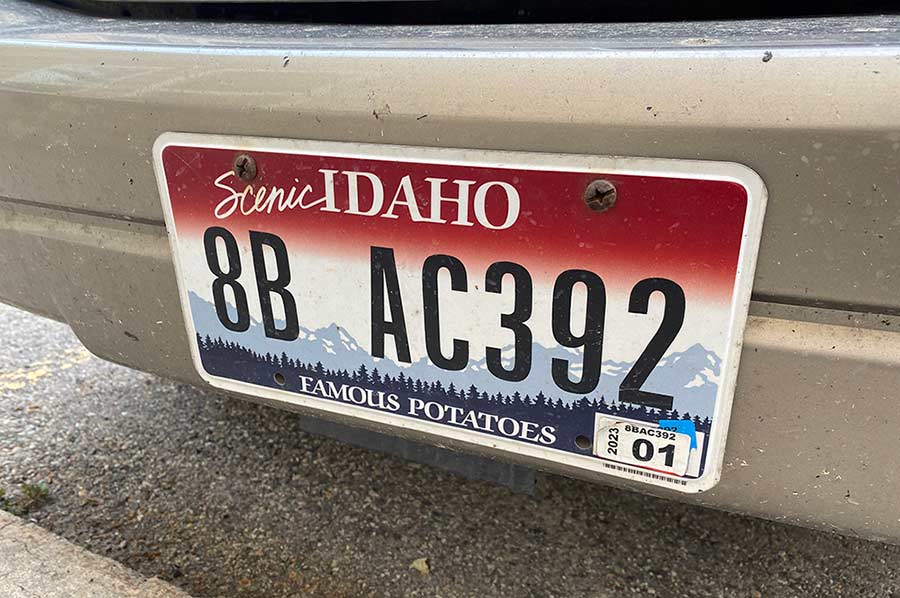

In [ ]:
from google.colab import files

# Upload an image file
uploaded = files.upload()

# Get the file name
file_name = list(uploaded.keys())[0]

# Load the image
image = cv2.imread(file_name)

# Display the original image
cv2_imshow(image)

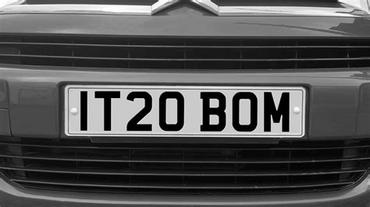

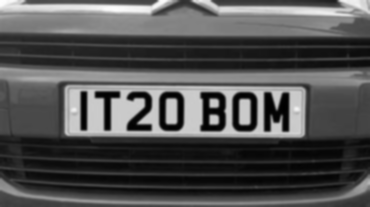

In [ ]:
# Convert the image to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
# Display the original image
cv2_imshow(gray_image)

# Apply a blur to the image
blurred_image = cv2.GaussianBlur(gray_image, (5, 5), 0)
# Display the original image
cv2_imshow(blurred_image)

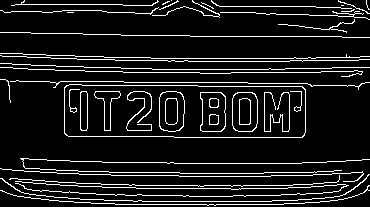

In [ ]:
# Use the Canny edge detector
edges = cv2.Canny(blurred_image, 50, 150)
# Display the original image
cv2_imshow(edges)

# Find contours in the edged image
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)


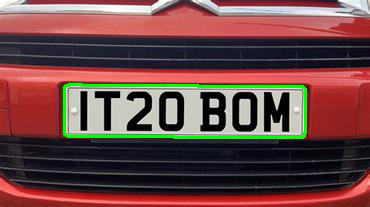

In [ ]:
# Filter contours based on area to find potential license plate regions
min_area = 1000
potential_plates = [cnt for cnt in contours if cv2.contourArea(cnt) > min_area]

# Sort potential plates by area in descending order
potential_plates = sorted(potential_plates, key=cv2.contourArea, reverse=True)

# Draw the potential plates on the original image
cv2.drawContours(image, potential_plates, -1, (0, 255, 0), 2)

# Display the image with potential plates
cv2_imshow(image)

License Plate Number: 1T20 BOM



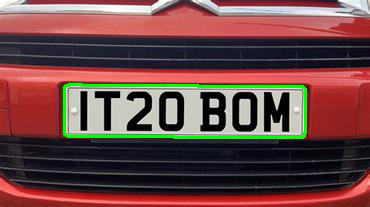

In [ ]:
# Iterate over potential plates and perform OCR
for plate in potential_plates:
    x, y, w, h = cv2.boundingRect(plate)
    roi = image[y:y+h, x:x+w]

    # Convert the region of interest (ROI) to grayscale
    roi_gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

    # Apply thresholding to improve OCR accuracy
    _, thresholded_roi = cv2.threshold(roi_gray, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

    # Use Tesseract OCR to recognize text
    plate_number = pytesseract.image_to_string(thresholded_roi, config='--psm 8 --oem 3')

    # Print the recognized license plate number
    print("License Plate Number:", plate_number)

# Display the image with bounding boxes and recognized numbers
cv2_imshow(image)